# Clean-Hour (Colab version): when is electricity cleanest?
**AI + Climate track.** This notebook runs top to bottom in Google Colab in about two minutes, with no downloads needed.
It shows the real evaluation code, an input-to-output example, and launches the Gradio app inside Colab.

[Open in Colab](https://colab.research.google.com/github/Harshal623/clean-hour/blob/main/notebooks/clean_hour_colab.ipynb) | [GitHub repo](https://github.com/Harshal623/clean-hour)

**What it does:** forecast the carbon intensity (grams of CO2 per kWh) of a regional power grid, then pick the cleanest 4-hour window within the time a household or data center can wait. The model was trained on 2023-2025 and tested on every day of 2026 (never shuffled).
**Honest scope:** average emissions of the whole regional grid, not marginal and not one town. Savings are measured against starting at midnight.

The saved forecasts used here (`results/test_predictions_all_ext.csv.gz`) were produced by `src/multigrid.py` from public EIA, Energy-Charts, NESO and Open-Meteo data. To regenerate everything from raw data, set `RUN_FULL = True` in section 5 (takes 10+ minutes and about 400 MB of downloads).

## 1. Setup

In [1]:
import os, subprocess, sys
if not os.path.exists("results/test_predictions_all_ext.csv.gz"):
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    else:  # Google Colab: get the code
        subprocess.run(["git", "clone", "-q", "https://github.com/Harshal623/clean-hour.git"], check=False)
        os.chdir("clean-hour")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=False)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
print("working in", os.getcwd())

working in C:\Users\Harsh\Downloads\hackathon 1\carbon


## 2. The data: saved 2026 test forecasts for five grids
One row per (grid, release day, hour). `j` = hours after local midnight of the release day (0-75); `y` = actual gCO2/kWh; `pred` = our forecast made at 18:00 the evening before; `clim` = the average for that hour of the week from training years; `persist` = repeat the latest same-hour value.

In [2]:
df = pd.read_csv("results/test_predictions_all_ext.csv.gz", parse_dates=["day"])
NAMES = {"pjm": "Virginia / Mid-Atlantic", "ciso": "California", "erco": "Texas", "de": "Germany", "gb": "Great Britain"}
print(df.groupby("grid").agg(days=("day", "nunique"), first=("day", "min"), last=("day", "max"), mean_gco2_kwh=("y", "mean")).round(1))
df.head(4)

      days      first       last  mean_gco2_kwh
grid                                           
ciso   314 2026-01-01 2026-11-10          175.2
de     314 2026-01-01 2026-11-10          309.3
erco   314 2026-01-01 2026-11-10          311.4
gb     314 2026-01-01 2026-11-10          124.4
pjm    311 2026-01-01 2026-11-10          348.1


C:\Users\Harsh\AppData\Local\Temp\ipykernel_35108\3919176600.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(df.groupby("grid").agg(days=("day", "nunique"), first=("day", "min"), last=("day", "max"), mean_gco2_kwh=("y", "mean")).round(1))


,grid,day,j,y,pred,pred_hist,clim,persist,hour,dow,temperature_2m,wind_speed_10m,cloud_cover,shortwave_radiation
0,pjm,2026-01-01,0,366.30,383.68,360.15,346.46,388.43,1,3,0.5,5.6,51.0,0.0
1,pjm,2026-01-01,1,371.88,379.03,357.96,342.71,386.99,2,3,0.5,10.6,98.0,0.0
2,pjm,2026-01-01,2,375.03,375.20,358.39,340.28,387.11,3,3,0.8,8.7,29.0,0.0
3,pjm,2026-01-01,3,377.88,375.11,357.81,340.02,384.88,4,3,0.9,10.0,3.0,0.0


## 3. The decision test (the core code)
A job of 4 hours is released at local midnight and may start any time within `slip` hours. For every 2026 day we pick the start whose forecast 4-hour average is lowest, then measure the **actual** intensity of that window. Strategies: start at midnight, repeat yesterday (persistence), average week (climatology), our model, and perfect hindsight.

In [3]:
JOB = 4

def window_means(profile):
    """Mean of every 4-hour window (index = start hour)."""
    return np.convolve(profile, np.ones(JOB) / JOB, mode="valid")

def best_start(profile, slip):
    # ignore windows that touch a missing hour; choose the lowest-forecast window among starts 0..slip
    return int(np.nanargmin(window_means(profile)[:slip + 1]))

def day_costs(day_df, slip):
    d = day_df.sort_values("j")
    y = d["y"].values
    actual = window_means(y)
    out = {"midnight": actual[0], "oracle": actual[best_start(y, slip)]}
    for name, col in [("persistence", "persist"), ("climatology", "clim"), ("model", "pred")]:
        prof = d[col].fillna(d["pred"]).values
        out[name] = actual[best_start(prof, slip)]
    return out

def evaluate(slip):
    rows = []
    for grid, g in df.groupby("grid"):
        days = [day_costs(d, slip) for _, d in g.groupby("day") if len(d) == 76]
        m = pd.DataFrame(days).mean()
        rows.append({"region": NAMES[grid], "days": len(days), **m.round(1).to_dict(),
                     "model % cleaner than midnight": round(100 * (m.midnight - m.model) / m.midnight, 1),
                     "average-week rule %": round(100 * (m.midnight - m.climatology) / m.midnight, 1),
                     "perfect hindsight %": round(100 * (m.midnight - m.oracle) / m.midnight, 1)})
    return pd.DataFrame(rows).set_index("region")

for slip in (24, 72):
    print(f"--- job can wait {slip} hours: mean gCO2/kWh of the chosen window (lower is better)")
    print(evaluate(slip).to_string())

--- job can wait 24 hours: mean gCO2/kWh of the chosen window (lower is better)


                         days  midnight  oracle  persistence  climatology  model  model % cleaner than midnight  average-week rule %  perfect hindsight %
region                                                                                                                                                   
California                314     220.0    97.7        100.6        106.3   99.7                           54.7                 51.7                 55.6
Germany                   314     364.3   186.4        199.6        195.3  194.8                           46.5                 46.4                 48.8
Texas                     314     338.2   229.8        238.6        239.1  237.8                           29.7                 29.3                 32.0
Great Britain             314     120.0    77.9         93.3        115.4   85.5                           28.8                  3.8                 35.1
Virginia / Mid-Atlantic   311     353.4   324.7        330.6        342.6  3

                         days  midnight  oracle  persistence  climatology  model  model % cleaner than midnight  average-week rule %  perfect hindsight %
region                                                                                                                                                   
California                314     220.0    80.5        100.6        103.8   90.1                           59.0                 52.8                 63.4
Germany                   314     364.3   156.3        199.6        188.0  174.5                           52.1                 48.4                 57.1
Texas                     314     338.2   202.5        238.6        235.0  220.6                           34.8                 30.5                 40.1
Great Britain             314     120.0    59.7         93.3        105.6   70.5                           41.2                 12.0                 50.3
Virginia / Mid-Atlantic   311     353.4   309.7        330.6        331.0  3

**Check against the saved results.** The table above should match `results/multigrid_summary.csv` (produced by the full pipeline, which also adds 95% bootstrap intervals) to within rounding of the stored forecasts.

In [4]:
S = pd.read_csv("results/multigrid_summary.csv")
chk = S[S.slip_h == 24].set_index("grid")[["immediate", "persistence", "climatology", "model", "oracle"]].round(1)
chk.index = [NAMES[g] for g in chk.index]
print("From results/multigrid_summary.csv (24 h):"); print(chk.to_string())

From results/multigrid_summary.csv (24 h):
                         immediate  persistence  climatology  model  oracle
Virginia / Mid-Atlantic      353.4        330.6        342.6  329.1   324.7
California                   220.0        100.6        106.3   99.7    97.7
Texas                        338.2        238.6        239.1  237.8   229.8
Germany                      364.3        199.6        195.3  194.8   186.4
Great Britain                120.0         93.3        115.4   85.5    77.9


## 4. Headline figure

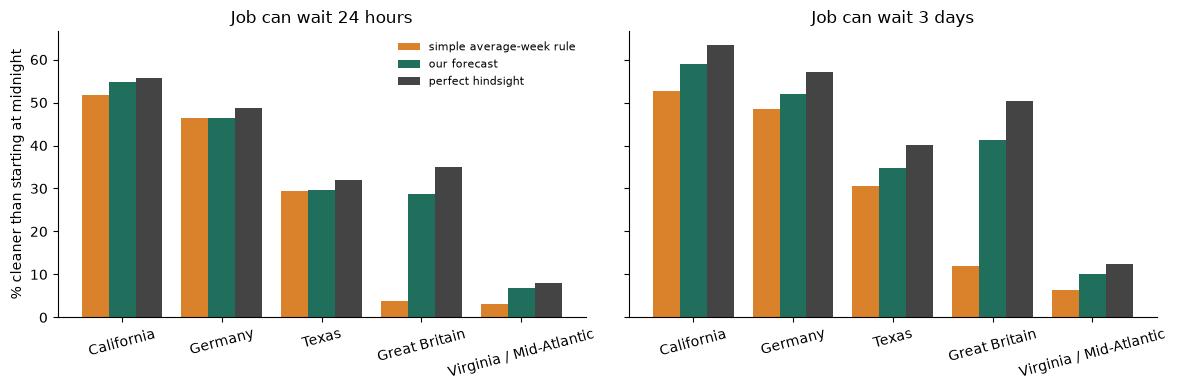

In [5]:
t = evaluate(24); u = evaluate(72)
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, tab, title in [(axs[0], t, "Job can wait 24 hours"), (axs[1], u, "Job can wait 3 days")]:
    x = np.arange(len(tab)); w = 0.27
    ax.bar(x - w, tab["average-week rule %"], w, label="simple average-week rule", color="#d9822b")
    ax.bar(x, tab["model % cleaner than midnight"], w, label="our forecast", color="#1f6f5c")
    ax.bar(x + w, tab["perfect hindsight %"], w, label="perfect hindsight", color="#444")
    ax.set_xticks(x); ax.set_xticklabels(tab.index, rotation=15); ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("% cleaner than starting at midnight"); axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Reading it honestly
- Shifting helps everywhere; the benefit is largest in solar-rich grids because midnight is when power is dirtiest.
- In California, Texas and Germany a simple "run at midday" rule is almost as good for same-day shifting. With 3 days of slack the model beats the rule in all five grids (intervals in `results/multigrid_summary.csv`).
- Britain's official NESO forecast beats ours, so the live tab uses theirs.
- Virginia is the flattest grid, so its savings are the smallest (about 7% at 24 h, 10% at 3 days).

## 5. One input, one output (what a household sees)

In [6]:
def recommend(grid, day, appliance_hours=4, slack_hours=24, kwh=10.0):
    d = df[(df.grid == grid) & (df.day == pd.Timestamp(day))].sort_values("j")
    pred, y = d["pred"].values, d["y"].values
    L = appliance_hours
    win = lambda a: np.convolve(a, np.ones(L) / L, mode="valid")
    start = int(np.nanargmin(win(pred)[:slack_hours + 1]))
    actual = win(y)
    saved_g = (actual[0] - actual[start]) * kwh
    hh = lambda h: f"{(h % 24 % 12) or 12} {'AM' if h % 24 < 12 else 'PM'}"
    print(f"{NAMES[grid]}, release day {day}, {L}-hour job, can wait {slack_hours} h")
    print(f"  Recommended start: day +{start // 24} at {hh(start)}  (midnight start would be {actual[0]:.0f} g/kWh, ours {actual[start]:.0f} g/kWh)")
    print(f"  CO2 avoided for {kwh:g} kWh: about {saved_g:,.0f} g  ({100 * (actual[0] - actual[start]) / actual[0]:.0f}% cleaner)")

sample_day = str(df[df.grid == "pjm"].day.sort_values().iloc[2000].date())
recommend("pjm", sample_day, appliance_hours=4, slack_hours=24, kwh=10)
recommend("gb", sample_day, appliance_hours=2, slack_hours=12, kwh=1.2)

Virginia / Mid-Atlantic, release day 2026-01-27, 4-hour job, can wait 24 h
  Recommended start: day +0 at 12 PM  (midnight start would be 410 g/kWh, ours 390 g/kWh)
  CO2 avoided for 10 kWh: about 200 g  (5% cleaner)
Great Britain, release day 2026-01-27, 2-hour job, can wait 12 h
  Recommended start: day +0 at 12 AM  (midnight start would be 58 g/kWh, ours 58 g/kWh)
  CO2 avoided for 1.2 kWh: about 0 g  (0% cleaner)


## 6. The interactive app inside Colab (Gradio)
In Colab this prints a public link and shows the app; locally it explains how to run it. The app has a Replay tab (tested on 2026 days) and a Live tab for Great Britain and Germany that needs internet.

In [7]:
import importlib.util, sys
spec = importlib.util.spec_from_file_location("clean_hour_app", "app/app.py")
mod = importlib.util.module_from_spec(spec); sys.argv = ["x"]; spec.loader.exec_module(mod)
if "google.colab" in sys.modules:
    mod.app.launch(share=True, debug=False)
else:
    print("App loaded OK. To open it locally run:  python app/app.py   then visit http://127.0.0.1:7860")

C:\Users\Harsh\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


App loaded OK. To open it locally run:  python app/app.py   then visit http://127.0.0.1:7860


## 7. Optional: rebuild everything from raw public data

In [8]:
RUN_FULL = False   # set True to re-download data and retrain (10+ minutes, about 400 MB)
if RUN_FULL:
    for script in ["src/grids.py", "src/multigrid.py"]:
        r = subprocess.run([sys.executable, "-W", "ignore", script], capture_output=True, text=True)
        print(r.stdout[-3000:], r.stderr[-1500:])
else:
    print("Skipped. Saved results are used above. Full pipeline: src/grids.py (data) then src/multigrid.py (models and tables).")

Skipped. Saved results are used above. Full pipeline: src/grids.py (data) then src/multigrid.py (models and tables).


## Sources and credits
EIA-930 grid data (https://www.eia.gov/electricity/gridmonitor/), Energy-Charts (https://api.energy-charts.info/), NESO Carbon Intensity API (https://carbonintensity.org.uk/), Open-Meteo (https://open-meteo.com/en/docs/historical-forecast-api), IPCC AR5 emission factors (https://www.ipcc.ch/report/ar5/wg3/), scikit-learn, pandas, Gradio. Full list: `CREDITS.md`. AI tool: Claude Code helped write and test this code; the team reviewed and can explain it.